<a href="https://colab.research.google.com/github/Parth-22k/ML-Lab/blob/main/Exp11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


First 5 Rows:
   Alcohol  Malic_Acid   Ash  Ash_Alcanity  Magnesium  Total_Phenols  \
0    14.23        1.71  2.43          15.6        127           2.80   
1    13.20        1.78  2.14          11.2        100           2.65   
2    13.16        2.36  2.67          18.6        101           2.80   
3    14.37        1.95  2.50          16.8        113           3.85   
4    13.24        2.59  2.87          21.0        118           2.80   

   Flavanoids  Nonflavanoid_Phenols  Proanthocyanins  Color_Intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   OD280  Proline  Customer_Segment  
0   3.92     1065                 1  
1 

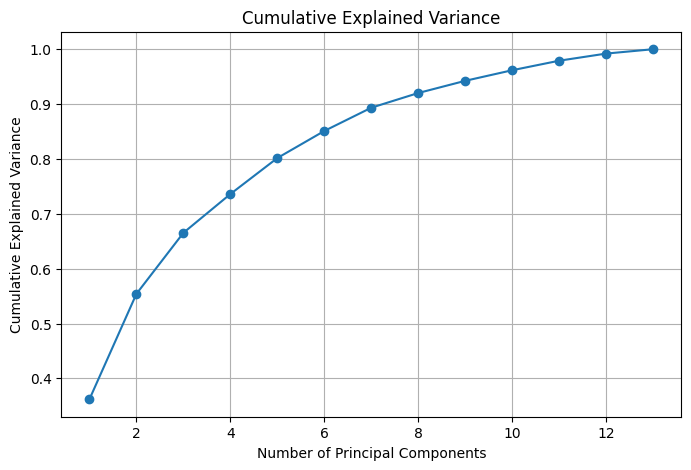


Original Data Shape: (178, 13)
PCA Reduced Shape: (178, 2)

Variance Captured by PC1 and PC2:
[0.36198848 0.1920749 ]


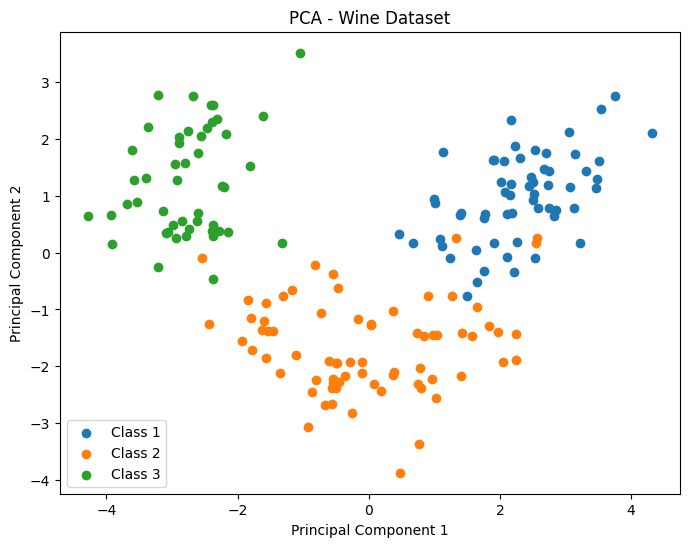


Accuracy on Original Data: 0.9722222222222222
Accuracy on PCA Reduced Data: 0.9166666666666666


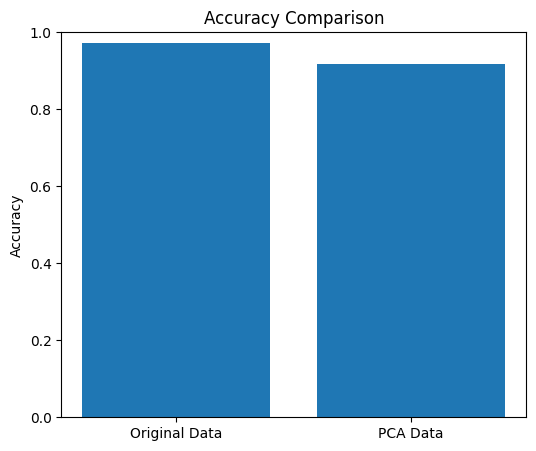

In [ ]:
# Experiment 11 - Dimensionality Reduction using PCA
# Dataset: Wine.csv

# --------------------------------------------------
# 1. Import Libraries
# --------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# --------------------------------------------------
# 2. Load Dataset
# --------------------------------------------------

df = pd.read_csv('/content/drive/MyDrive/ML/Wine.csv')

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)


# --------------------------------------------------
# 3. Separate Features and Target
# --------------------------------------------------

X = df.drop('Customer_Segment', axis=1)
y = df['Customer_Segment']

print("\nNumber of Features:", X.shape[1])

print("\nClasses:")
print(y.unique())


# --------------------------------------------------
# 4. Feature Scaling
# --------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


# --------------------------------------------------
# 5. Apply PCA for Explained Variance
# --------------------------------------------------

pca_all = PCA()

pca_all.fit(X_scaled)

explained_variance = pca_all.explained_variance_ratio_

print("\nExplained Variance Ratio:")
print(explained_variance)


# --------------------------------------------------
# 6. Cumulative Explained Variance
# --------------------------------------------------

cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.grid()
plt.show()


# --------------------------------------------------
# 7. Reduce 13 Features to 2 Components
# --------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("\nOriginal Data Shape:", X.shape)
print("PCA Reduced Shape:", X_pca.shape)

print("\nVariance Captured by PC1 and PC2:")
print(pca.explained_variance_ratio_)


# --------------------------------------------------
# 8. PCA Scatter Plot
# --------------------------------------------------

plt.figure(figsize=(8, 6))

for class_value in np.unique(y):

    plt.scatter(
        X_pca[y == class_value, 0],
        X_pca[y == class_value, 1],
        label="Class " + str(class_value)
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA - Wine Dataset")

plt.legend()

plt.show()


# --------------------------------------------------
# 9. Split Original Scaled Data
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 10. Logistic Regression on Original Data
# --------------------------------------------------

model_original = LogisticRegression(max_iter=200)

model_original.fit(X_train, y_train)

y_pred_original = model_original.predict(X_test)

original_accuracy = accuracy_score(
    y_test,
    y_pred_original
)

print("\nAccuracy on Original Data:",
      original_accuracy)


# --------------------------------------------------
# 11. Split PCA Reduced Data
# --------------------------------------------------

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(
    X_pca,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 12. Logistic Regression on PCA Data
# --------------------------------------------------

model_pca = LogisticRegression(max_iter=200)

model_pca.fit(X_train_pca, y_train_pca)

y_pred_pca = model_pca.predict(X_test_pca)

pca_accuracy = accuracy_score(
    y_test_pca,
    y_pred_pca
)

print("Accuracy on PCA Reduced Data:",
      pca_accuracy)


# --------------------------------------------------
# 13. Accuracy Comparison Graph
# --------------------------------------------------

labels = ["Original Data", "PCA Data"]

accuracies = [
    original_accuracy,
    pca_accuracy
]

plt.figure(figsize=(6, 5))

plt.bar(labels, accuracies)

plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")

plt.ylim(0, 1)

plt.show()